# Lead Scorer — Análise exploratória do pipeline de vendas

**Challenge 003 · G4 AI Master · Vendas / RevOps**

**Pergunta de negócio:** os vendedores gastam tempo demais em deals que não vão fechar e deixam boas oportunidades esfriarem. Antes de construir qualquer scoring, preciso responder:

1. Os dados são confiáveis? O que precisa ser limpo?
2. **O que realmente separa um deal ganho de um perdido?** Ou seja, quais sinais existem antes de o deal fechar.
3. Como está o pipeline aberto hoje, e onde está o desperdício de tempo?

**Princípio deste notebook:** toda afirmação vem com o número que a sustenta. Quando um padrão parece interessante, eu testo se ele é maior que o acaso e se teria funcionado **no passado sem olhar o futuro** (backtest sem vazamento).

| Etapa | O que faz |
|---|---|
| 1 | Carga dos dados |
| 2 | Qualidade e integridade |
| 3 | Limpeza |
| 4 | Visão geral do funil |
| 5 | Atributos estáticos: produto, setor, região, manager, porte |
| 6 | Vendedores: diferença real ou ruído? |
| 7 | Tempo no pipeline: o sinal que existe |
| 8 | Sazonalidade de fechamento |
| 9 | Valor dos deals |
| 10 | Backtest sem vazamento: o histórico prevê o resultado? |
| 11 | Pipeline aberto hoje |
| 12 | Robustez: descritiva, outliers, possíveis erros, censura, correlações e regressão |
| 13 | Conclusões e implicações para o scoring |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
from sklearn.metrics import roc_auc_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# Paleta: azul = ganho / série principal, laranja = perdido / alerta, cinza = referência
AZUL, LARANJA, VERDE_AGUA, CINZA, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.figsize": (10, 4.2), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left",
    "xtick.color": TINTA, "ytick.color": TINTA,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "font.size": 10, "legend.frameon": False,
})

DATA = "../data"

## 1. Carga dos dados

Quatro tabelas de um CRM. A `sales_pipeline` é a central: cada linha é uma oportunidade e se liga às outras três por `sales_agent`, `product` e `account`.

Carrego tudo **cru**, sem converter nada ainda. Primeiro quero ver os dados como vieram.

In [2]:
accounts = pd.read_csv(f"{DATA}/accounts.csv")
products = pd.read_csv(f"{DATA}/products.csv")
teams    = pd.read_csv(f"{DATA}/sales_teams.csv")
pipeline = pd.read_csv(f"{DATA}/sales_pipeline.csv")

for nome, df in [("accounts", accounts), ("products", products), ("sales_teams", teams), ("sales_pipeline", pipeline)]:
    print(f"{nome:<15} {df.shape[0]:>5} linhas x {df.shape[1]} colunas")

accounts           85 linhas x 7 colunas
products            7 linhas x 3 colunas
sales_teams        35 linhas x 3 colunas
sales_pipeline   8800 linhas x 8 colunas


In [3]:
pipeline.head()

,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value
0,1C1I7A6R,Moses Frase,GTX Plus Basic,Cancity,Won,2016-10-20,2017-03-01,"1,054.000"
1,Z063OYW0,Darcel Schlecht,GTXPro,Isdom,Won,2016-10-25,2017-03-11,"4,514.000"
2,EC4QE1BX,Darcel Schlecht,MG Special,Cancity,Won,2016-10-25,2017-03-07,50.000
3,MV1LWRNH,Moses Frase,GTX Basic,Codehow,Won,2016-10-25,2017-03-09,588.000
4,PE84CX4O,Zane Levy,GTX Basic,Hatfan,Won,2016-10-25,2017-03-02,517.000


In [4]:
pipeline.info()

<class 'pandas.DataFrame'>
RangeIndex: 8800 entries, 0 to 8799
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   opportunity_id  8800 non-null   str    
 1   sales_agent     8800 non-null   str    
 2   product         8800 non-null   str    
 3   account         7375 non-null   str    
 4   deal_stage      8800 non-null   str    
 5   engage_date     8300 non-null   str    
 6   close_date      6711 non-null   str    
 7   close_value     6711 non-null   float64
dtypes: float64(1), str(7)
memory usage: 550.1 KB


In [5]:
products

,product,series,sales_price
0,GTX Basic,GTX,550
1,GTX Pro,GTX,4821
2,MG Special,MG,55
3,MG Advanced,MG,3393
4,GTX Plus Pro,GTX,5482
5,GTX Plus Basic,GTX,1096
6,GTK 500,GTK,26768


## 2. Qualidade e integridade

Antes de analisar, verifico cinco coisas:

1. **Nulos por estágio.** Faltar `close_date` num deal aberto é esperado. Faltar a conta, não.
2. **Integridade das chaves.** Todo produto, vendedor e conta do pipeline existe na tabela de cadastro?
3. **Duplicatas** de `opportunity_id`.
4. **Regras de negócio.** Deal ganho tem valor maior que zero? Perdido tem valor zero? Fechamento vem depois do engajamento?
5. **Categorias escritas de formas diferentes.**

In [6]:
# 2.1 Nulos por estágio
pipeline.isna().groupby(pipeline["deal_stage"]).sum()

,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value
deal_stage,,,,,,,,
Engaging,0,0,0,1088,0,0,1589,1589
Lost,0,0,0,0,0,0,0,0
Prospecting,0,0,0,337,0,500,500,500
Won,0,0,0,0,0,0,0,0


**Achado:** `close_date` e `close_value` vazios nos abertos são esperados. Mas **1.425 deals abertos não têm conta**: 337 em Prospecting e 1.088 em Engaging. Isso é um problema operacional do CRM, não da análise, e precisa aparecer na ferramenta.

In [7]:
# 2.2 Integridade das chaves
print("Produtos no pipeline fora do catálogo:", sorted(set(pipeline["product"]) - set(products["product"])))
print("Vendedores no pipeline fora do cadastro:", sorted(set(pipeline["sales_agent"]) - set(teams["sales_agent"])))
print("Vendedores cadastrados sem nenhum deal:", sorted(set(teams["sales_agent"]) - set(pipeline["sales_agent"])))
print("Contas no pipeline fora do cadastro:", sorted(set(pipeline["account"].dropna()) - set(accounts["account"])))
print("Contas cadastradas sem nenhum deal:", sorted(set(accounts["account"]) - set(pipeline["account"].dropna())))

Produtos no pipeline fora do catálogo: ['GTXPro']
Vendedores no pipeline fora do cadastro: []
Vendedores cadastrados sem nenhum deal: ['Carl Lin', 'Carol Thompson', 'Elizabeth Anderson', 'Mei-Mei Johns', 'Natalya Ivanova']
Contas no pipeline fora do cadastro: []
Contas cadastradas sem nenhum deal: []


In [8]:
# 2.3 Duplicatas e 2.4 regras de negócio
p = pipeline.assign(engage_date=pd.to_datetime(pipeline.engage_date), close_date=pd.to_datetime(pipeline.close_date))
regras = {
    "opportunity_id duplicado": p.opportunity_id.duplicated().sum(),
    "Won com close_value <= 0": ((p.deal_stage == "Won") & (p.close_value <= 0)).sum(),
    "Lost com close_value != 0": ((p.deal_stage == "Lost") & (p.close_value != 0)).sum(),
    "close_date antes de engage_date": (p.close_date < p.engage_date).sum(),
    "Prospecting com engage_date": ((p.deal_stage == "Prospecting") & p.engage_date.notna()).sum(),
    "Engaging sem engage_date": ((p.deal_stage == "Engaging") & p.engage_date.isna()).sum(),
}
pd.Series(regras, name="ocorrências").to_frame()

,ocorrências
opportunity_id duplicado,0
Won com close_value <= 0,0
Lost com close_value != 0,0
close_date antes de engage_date,0
Prospecting com engage_date,0
Engaging sem engage_date,0


In [9]:
# 2.5 Categorias com grafia inconsistente
print("Setores:", sorted(accounts.sector.unique()))
print("Países:", sorted(accounts.office_location.unique()))
print("Produtos no pipeline:", sorted(pipeline["product"].unique()))

Setores: ['employment', 'entertainment', 'finance', 'marketing', 'medical', 'retail', 'services', 'software', 'technolgy', 'telecommunications']
Países: ['Belgium', 'Brazil', 'China', 'Germany', 'Italy', 'Japan', 'Jordan', 'Kenya', 'Korea', 'Norway', 'Panama', 'Philipines', 'Poland', 'Romania', 'United States']
Produtos no pipeline: ['GTK 500', 'GTX Basic', 'GTX Plus Basic', 'GTX Plus Pro', 'GTXPro', 'MG Advanced', 'MG Special']


**Resumo da qualidade:**

| Problema | Impacto | Tratamento |
|---|---|---|
| `GTXPro` no pipeline × `GTX Pro` no catálogo | O join com preço falha para 1.480 deals | Normalizar para `GTX Pro` |
| Setor `technolgy` | Grafia errada | Corrigir para `technology` |
| País `Philipines` | Grafia errada | Corrigir para `Philippines` |
| 1.425 deals abertos sem conta | Não dá para usar setor ou porte em 68% do pipeline aberto | Sinalizar na ferramenta como "completar cadastro" |
| 5 vendedores sem nenhum deal | Ruído nos filtros | Manter no cadastro, mas fora dos rankings |

As regras de negócio (valores, datas, duplicatas) estão consistentes.

## 3. Limpeza

Coloco tudo numa função, porque a mesma limpeza vai ser reaproveitada no carregamento do Supabase. Também defino a **data de referência**: o dataset é um retrato do CRM. A última data registrada é o "hoje" da análise, e é contra ela que mediremos a idade dos deals abertos.

In [10]:
def limpar(pipeline, accounts, products, teams):
    pipe = pipeline.copy()
    pipe["product"] = pipe["product"].replace({"GTXPro": "GTX Pro"})
    pipe["engage_date"] = pd.to_datetime(pipe["engage_date"])
    pipe["close_date"] = pd.to_datetime(pipe["close_date"])

    acc = accounts.copy()
    acc["sector"] = acc["sector"].replace({"technolgy": "technology"})
    acc["office_location"] = acc["office_location"].replace({"Philipines": "Philippines"})

    df = (pipe.merge(teams, on="sales_agent", how="left", validate="many_to_one")
              .merge(products, on="product", how="left", validate="many_to_one")
              .merge(acc, on="account", how="left", validate="many_to_one"))
    assert df["sales_price"].notna().all(), "produto sem preço após o join"
    assert df["manager"].notna().all(), "vendedor sem time após o join"
    return df

df = limpar(pipeline, accounts, products, teams)
DATA_REF = max(df.engage_date.max(), df.close_date.max())
print("Data de referência (hoje do snapshot):", DATA_REF.date())
print("Linhas após joins:", len(df))

Data de referência (hoje do snapshot): 2017-12-31
Linhas após joins: 8800


In [11]:
fechados = df[df.deal_stage.isin(["Won", "Lost"])].copy()
fechados["ganho"] = (fechados.deal_stage == "Won").astype(int)
fechados["ciclo_dias"] = (fechados.close_date - fechados.engage_date).dt.days

abertos = df[df.deal_stage.isin(["Prospecting", "Engaging"])].copy()
abertos["idade_dias"] = (DATA_REF - abertos.engage_date).dt.days

print(f"Fechados: {len(fechados):,} | Abertos: {len(abertos):,}")

Fechados: 6,711 | Abertos: 2,089


## 4. Visão geral do funil

In [12]:
funil = df.groupby("deal_stage").agg(deals=("opportunity_id", "count"),
                                     valor_lista=("sales_price", "sum")).reindex(["Prospecting", "Engaging", "Won", "Lost"])
funil["% deals"] = funil.deals / funil.deals.sum()
taxa_geral = fechados.ganho.mean()
print(f"Taxa de ganho geral (Won / fechados): {taxa_geral:.1%}  —  {fechados.ganho.sum():,} de {len(fechados):,}")
funil

Taxa de ganho geral (Won / fechados): 63.2%  —  4,238 de 6,711


,deals,valor_lista,% deals
deal_stage,,,
Prospecting,500,1073986,0.057
Engaging,1589,3892229,0.181
Won,4238,10023482,0.482
Lost,2473,5946468,0.281


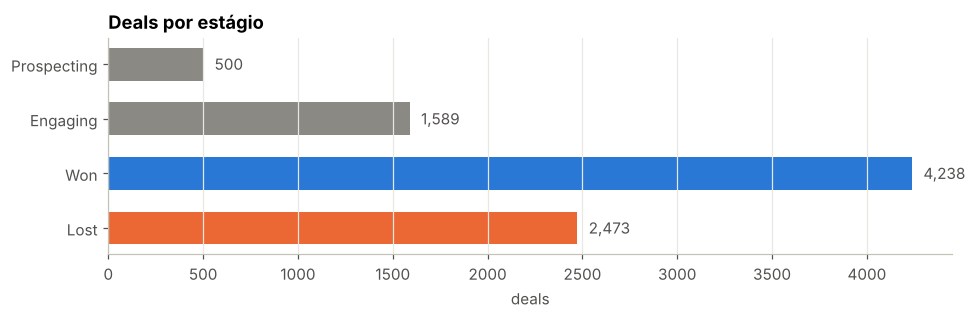

In [13]:
fig, ax = plt.subplots(figsize=(9, 3))
cores = [CINZA, CINZA, AZUL, LARANJA]
ax.barh(funil.index[::-1], funil.deals[::-1], color=cores[::-1], height=0.6)
for i, v in enumerate(funil.deals[::-1]):
    ax.text(v + 60, i, f"{v:,}", va="center", color=TINTA)
ax.set_title("Deals por estágio")
ax.set_xlabel("deals")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

63% dos deals fechados são ganhos. É uma taxa alta e **o ponto de partida de qualquer score**: um deal "médio" tem cerca de 63% de chance. A pergunta é quais deals se afastam disso.

## 5. Atributos estáticos: produto, setor, região, manager, porte

É aqui que um scoring ingênuo começa: "o setor X ganha mais, então pontua mais". Para cada atributo calculo:

- a taxa de ganho com **intervalo de confiança de 95% (Wilson)**, para não confundir uma amostra pequena com um padrão real;
- um **teste qui-quadrado**, que responde se as diferenças entre categorias são maiores que o esperado por acaso.

In [14]:
def wilson(k, n, z=1.96):
    p = k / n
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    meia = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centro - meia, centro + meia

def taxa_por(col, data=fechados, min_n=0):
    g = data.groupby(col, observed=True).ganho.agg(ganhos="sum", n="count")
    g = g[g.n >= min_n]
    g["taxa"] = g.ganhos / g.n
    g["ic_inf"], g["ic_sup"] = wilson(g.ganhos, g.n)
    tab = pd.crosstab(data[col], data.ganho)
    chi2, pval, _, _ = stats.chi2_contingency(tab)
    return g.sort_values("taxa"), pval

def plot_taxas(g, titulo, ax):
    y = np.arange(len(g))
    ax.errorbar(g.taxa, y, xerr=[g.taxa - g.ic_inf, g.ic_sup - g.taxa], fmt="o", color=AZUL,
                ecolor="#9cc0ea", elinewidth=2, capsize=0, markersize=6)
    ax.axvline(taxa_geral, color=CINZA, ls="--", lw=1)
    ax.set_yticks(y, [f"{i}  (n={n:,})" for i, n in zip(g.index, g.n)])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_xlim(0.40, 0.90)
    ax.set_title(titulo)
    ax.grid(axis="y", visible=False)

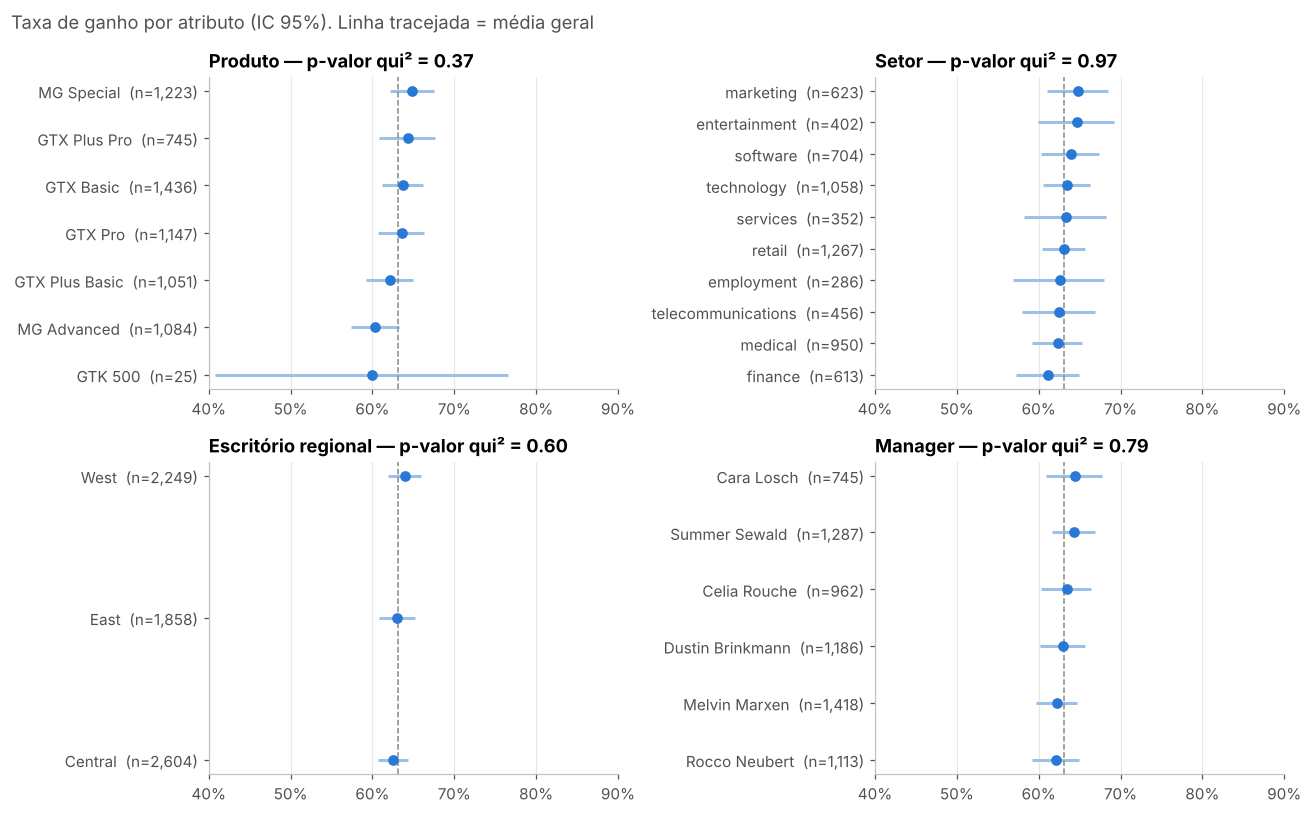

In [15]:
resumo_chi = {}
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (col, titulo) in zip(axes.flat, [("product", "Produto"), ("sector", "Setor"),
                                         ("regional_office", "Escritório regional"), ("manager", "Manager")]):
    g, pval = taxa_por(col)
    resumo_chi[titulo] = pval
    plot_taxas(g, f"{titulo} — p-valor qui² = {pval:.2f}", ax)
fig.suptitle("Taxa de ganho por atributo (IC 95%). Linha tracejada = média geral", x=0.01, ha="left", color=TINTA)
plt.tight_layout(); plt.show()

**Leitura:** todas as categorias ficam numa faixa estreita (cerca de 60% a 65%), os intervalos de confiança se sobrepõem e nenhum qui-quadrado chega perto de 0,05. **Produto, setor, região e manager não distinguem deals que ganham de deals que perdem.**

In [16]:
# Porte e localização da conta (só deals com conta preenchida; todos os fechados têm)
f = fechados.copy()
f["faixa_receita"] = pd.qcut(f.revenue, 4, labels=["Q1 menor", "Q2", "Q3", "Q4 maior"])
f["faixa_funcionarios"] = pd.qcut(f.employees, 4, labels=["Q1 menor", "Q2", "Q3", "Q4 maior"])
f["subsidiaria"] = np.where(f.subsidiary_of.notna(), "sim", "não")
f["idade_empresa"] = pd.qcut(2017 - f.year_established, 4, labels=["Q1 mais nova", "Q2", "Q3", "Q4 mais antiga"])
f["sede_eua"] = np.where(f.office_location == "United States", "EUA", "fora dos EUA")

linhas = []
for col in ["faixa_receita", "faixa_funcionarios", "idade_empresa", "subsidiaria", "sede_eua"]:
    g, pval = taxa_por(col, f)
    resumo_chi[col] = pval
    linhas.append({"atributo": col, "menor taxa": f"{g.taxa.min():.1%}", "maior taxa": f"{g.taxa.max():.1%}",
                   "amplitude (p.p.)": round((g.taxa.max() - g.taxa.min()) * 100, 1), "p-valor qui²": round(pval, 3)})
pd.DataFrame(linhas)

,atributo,menor taxa,maior taxa,amplitude (p.p.),p-valor qui²
0,faixa_receita,61.3%,65.9%,4.500,0.032
1,faixa_funcionarios,61.4%,64.1%,2.600,0.362
2,idade_empresa,62.5%,64.4%,2.000,0.652
3,subsidiaria,63.1%,63.6%,0.600,0.740
4,sede_eua,62.6%,63.3%,0.600,0.712


In [17]:
# Países: vários com amostra pequena. Mostra por que o IC importa.
g, pval = taxa_por("office_location", f)
print(f"p-valor qui² por país: {pval:.3f}")
g[["ganhos", "n", "taxa", "ic_inf", "ic_sup"]]

p-valor qui² por país: 0.419


,ganhos,n,taxa,ic_inf,ic_sup
office_location,,,,,
Romania,23,41,0.561,0.410,0.701
Korea,111,193,0.575,0.505,0.643
Norway,50,85,0.588,0.482,0.687
Philippines,50,85,0.588,0.482,0.687
Belgium,63,104,0.606,0.510,0.694
Japan,46,75,0.613,0.500,0.715
Brazil,32,52,0.615,0.480,0.735
Kenya,53,86,0.616,0.511,0.712
Italy,54,87,0.621,0.516,0.715


**Leitura:** a faixa de receita até chega a p < 0,05, mas sem ordem nenhuma (Q3 alto, Q4 baixo, amplitude de cerca de 4 p.p.). Não há uma história do tipo "conta maior ganha mais". Quando se testam muitos atributos, um ou outro passa de 0,05 por puro acaso.

Países como Panamá (75%) ou Romênia (56%) parecem extremos, mas têm entre 40 e 100 deals. Com exceção do Panamá, todos os ICs cruzam a média. E com 15 países testados, é esperado que cerca de 1 passe por puro acaso; o teste conjunto dá p = 0,42. **É o tipo de "insight" que uma IA aponta sem checar.**

## 6. Vendedores: diferença real ou ruído?

A taxa de ganho por vendedor vai de cerca de 55% a 70%. Parece muito. Mas, com 80 a 300 deals por pessoa, **quanto de variação apareceria mesmo se todos fossem iguais?**

Para responder, faço uma **simulação**. Sorteio 10 mil vezes resultados binomiais com a taxa geral e o mesmo número de deals de cada vendedor, e comparo a dispersão simulada com a dispersão real.

In [18]:
vend, pval_vend = taxa_por("sales_agent")
rng = np.random.default_rng(42)
sim = rng.binomial(vend.n.values[None, :], taxa_geral, size=(10_000, len(vend))) / vend.n.values[None, :]
dp_sim = sim.std(axis=1)
dp_real = vend.taxa.std(ddof=0)
p_sim = (dp_sim >= dp_real).mean()
print(f"Desvio-padrão real entre vendedores: {dp_real:.4f}")
print(f"Desvio-padrão esperado só por acaso: {dp_sim.mean():.4f} (IC 95%: {np.quantile(dp_sim, .025):.4f}–{np.quantile(dp_sim, .975):.4f})")
print(f"Probabilidade de o acaso gerar dispersão igual ou maior: {p_sim:.1%}  |  qui² p = {pval_vend:.3f}")

Desvio-padrão real entre vendedores: 0.0360
Desvio-padrão esperado só por acaso: 0.0339 (IC 95%: 0.0252–0.0438)
Probabilidade de o acaso gerar dispersão igual ou maior: 31.4%  |  qui² p = 0.264


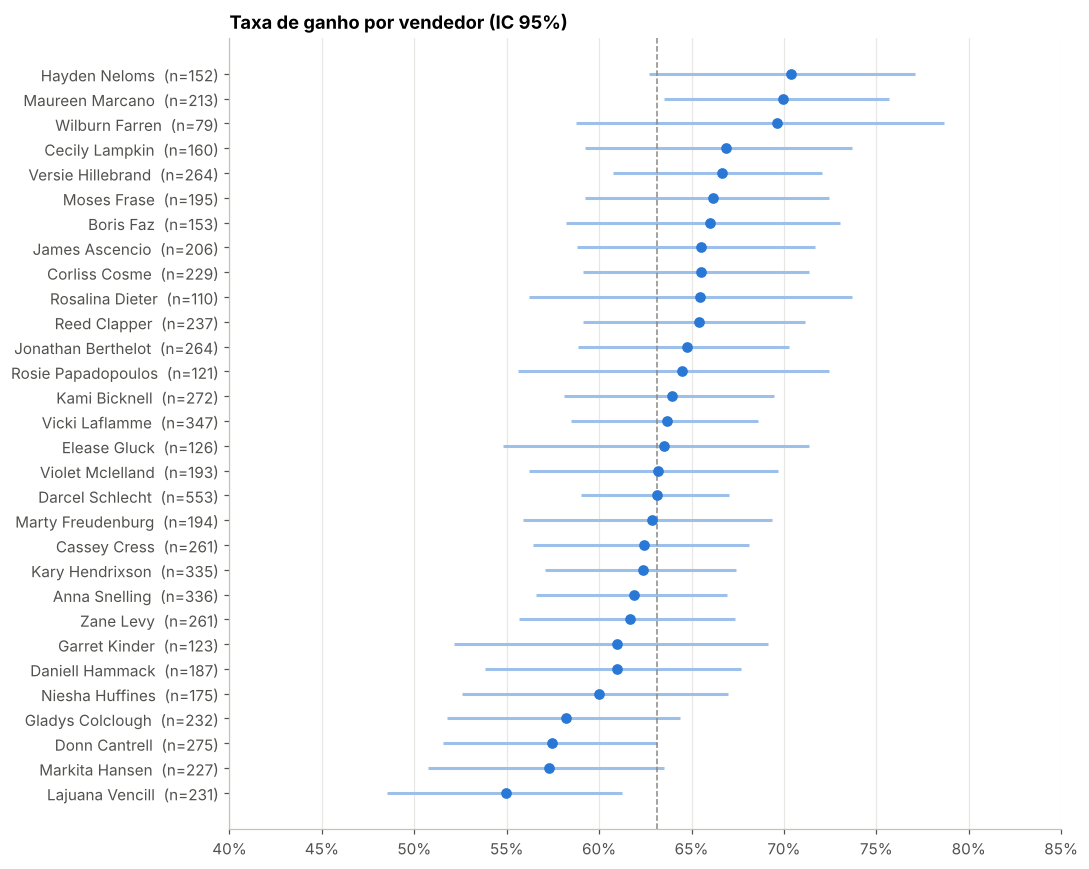

In [19]:
fig, ax = plt.subplots(figsize=(10, 8))
plot_taxas(vend, "Taxa de ganho por vendedor (IC 95%)", ax)
ax.set_xlim(0.40, 0.85)
plt.tight_layout(); plt.show()

In [20]:
# Vendedor x produto: as combinações extremas se sustentam?
vp = fechados.groupby(["sales_agent", "product"]).ganho.agg(ganhos="sum", n="count")
vp = vp[vp.n >= 30]
vp["taxa"] = vp.ganhos / vp.n
vp["ic_inf"], vp["ic_sup"] = wilson(vp.ganhos, vp.n)
print(f"Combinações vendedor x produto com n >= 30: {len(vp)}")
print(f"Com IC 95% inteiramente acima da média geral: {(vp.ic_inf > taxa_geral).sum()}")
print(f"Com IC 95% inteiramente abaixo da média geral: {(vp.ic_sup < taxa_geral).sum()}")
print(f"Esperado por acaso (5% de {len(vp)} testes): ~{0.05 * len(vp):.0f}")
pd.concat([vp.sort_values("taxa").head(4), vp.sort_values("taxa").tail(4)])

Combinações vendedor x produto com n >= 30: 89
Com IC 95% inteiramente acima da média geral: 5
Com IC 95% inteiramente abaixo da média geral: 1
Esperado por acaso (5% de 89 testes): ~4


ganhos   n  taxa  ic_inf  ic_sup
sales_agent        product                                       
Anna Snelling      MG Advanced       21  45 0.467   0.329   0.609
Marty Freudenburg  MG Advanced       20  41 0.488   0.343   0.635
Lajuana Vencill    MG Special        18  36 0.500   0.345   0.655
                   MG Advanced       28  55 0.509   0.381   0.636
Corliss Cosme      GTX Plus Pro      30  38 0.789   0.637   0.889
Moses Frase        GTX Basic         47  59 0.797   0.677   0.880
Rosie Papadopoulos GTX Pro           25  31 0.806   0.637   0.908
Maureen Marcano    GTX Plus Pro      26  32 0.812   0.647   0.911

**Leitura:** a dispersão entre vendedores é **compatível com o acaso**. As combinações vendedor × produto que parecem estrelas ou desastres aparecem em quantidade próxima da que 5% de falsos positivos geraria. A seção 10 tira a prova final: se esse "talento" fosse real, a taxa passada de cada vendedor preveria os deals seguintes dele.

## 7. Tempo no pipeline: o sinal que existe

O `ciclo_dias` (do engajamento ao fechamento) **não está disponível** para um deal aberto, porque ele só existe depois do fechamento. Usá-lo direto no score seria vazamento. O que existe para um deal aberto é a **idade até hoje**.

A pergunta certa é condicional: *dado que um deal já sobreviveu X dias sem fechar, qual a chance de ele ser ganho?*

In [21]:
print(fechados.groupby("deal_stage").ciclo_dias.describe())
CICLO_MAX = fechados.ciclo_dias.max()
P90 = fechados.ciclo_dias.quantile(0.90)
print(f"\nCiclo máximo observado: {CICLO_MAX} dias | percentil 90: {P90:.0f} dias")

               count   mean    std   min   25%    50%    75%     max
deal_stage                                                          
Lost       2,473.000 41.479 40.041 1.000 7.000 14.000 79.000 138.000
Won        4,238.000 51.782 41.172 1.000 9.000 57.000 88.000 138.000

Ciclo máximo observado: 138 dias | percentil 90: 104 dias


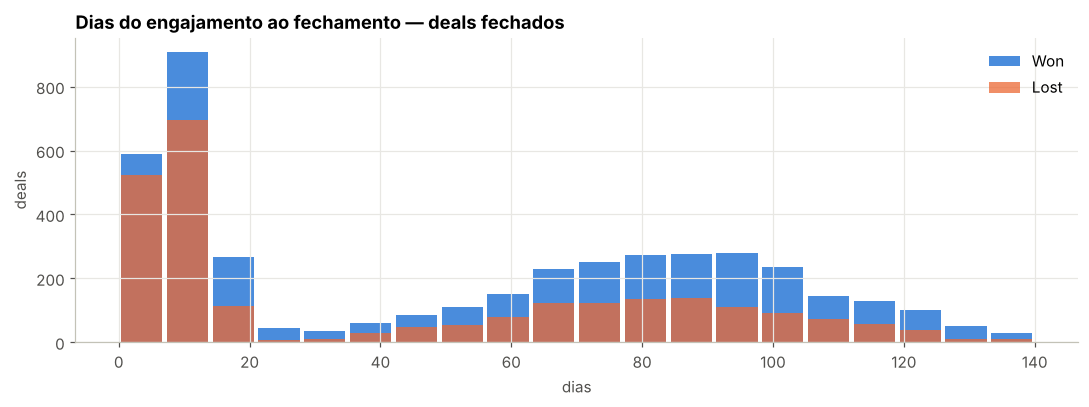

In [22]:
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.arange(0, CICLO_MAX + 7, 7)
ax.hist(fechados.loc[fechados.ganho == 1, "ciclo_dias"], bins=bins, color=AZUL, alpha=0.85, label="Won", rwidth=0.9)
ax.hist(fechados.loc[fechados.ganho == 0, "ciclo_dias"], bins=bins, color=LARANJA, alpha=0.75, label="Lost", rwidth=0.9)
ax.set_title("Dias do engajamento ao fechamento — deals fechados")
ax.set_xlabel("dias"); ax.set_ylabel("deals"); ax.legend()
plt.tight_layout(); plt.show()

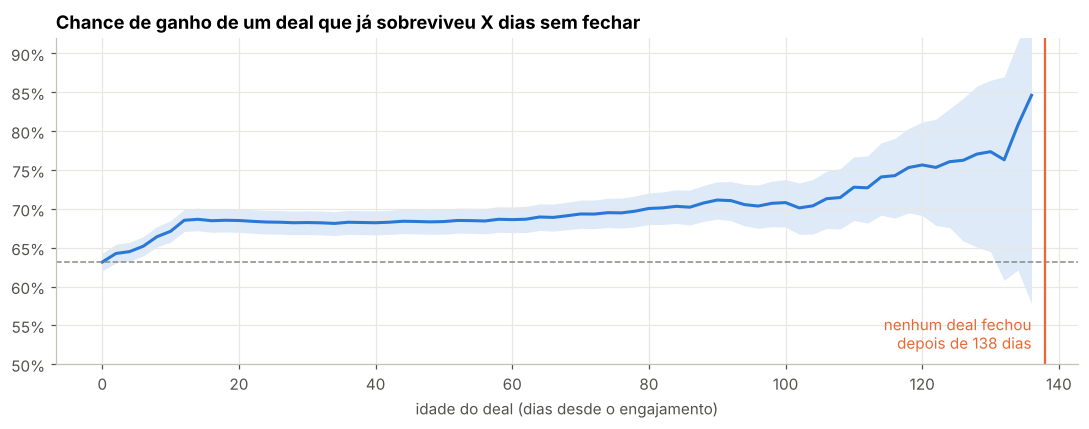

,idade,n_sobreviventes,p_ganho,ic_inf,ic_sup
0,0,6711,0.632,0.620,0.643
7,14,3905,0.687,0.672,0.701
14,28,3561,0.682,0.667,0.697
21,42,3414,0.683,0.667,0.698
28,56,3108,0.684,0.668,0.700
35,70,2482,0.693,0.675,0.711
42,84,1705,0.703,0.681,0.724
49,98,922,0.707,0.677,0.736
56,112,403,0.727,0.682,0.768
63,126,80,0.762,0.659,0.842


In [23]:
idades = np.arange(0, CICLO_MAX, 2)
curva = pd.DataFrame({
    "idade": idades,
    "n_sobreviventes": [(fechados.ciclo_dias > a).sum() for a in idades],
    "p_ganho": [fechados.loc[fechados.ciclo_dias > a, "ganho"].mean() for a in idades],
})
curva["ic_inf"], curva["ic_sup"] = wilson(curva.p_ganho * curva.n_sobreviventes, curva.n_sobreviventes)

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(curva.idade, curva.ic_inf, curva.ic_sup, color=AZUL, alpha=0.15, lw=0)
ax.plot(curva.idade, curva.p_ganho, color=AZUL, lw=2)
ax.axhline(taxa_geral, color=CINZA, ls="--", lw=1)
ax.axvline(CICLO_MAX, color=LARANJA, lw=1.5)
ax.text(CICLO_MAX - 2, 0.52, f"nenhum deal fechou\ndepois de {CICLO_MAX} dias", ha="right", color=LARANJA)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(0.5, 0.92)
ax.set_title("Chance de ganho de um deal que já sobreviveu X dias sem fechar")
ax.set_xlabel("idade do deal (dias desde o engajamento)")
plt.tight_layout(); plt.show()
curva.iloc[::7]

**Leitura:** este é o padrão mais consistente do dataset.

- **Os primeiros 14 dias concentram as perdas.** A mediana dos perdidos é de 14 dias, contra 57 dos ganhos. Deal que vai perder, perde cedo.
- Quem passa dessa fase vai subindo: de **63% no dia zero para 69% depois de 14 dias e cerca de 75% acima de 120 dias.**
- **Existe um teto duro: nenhum deal na história fechou depois de 138 dias.** Um deal aberto há mais tempo que isso está fora de qualquer padrão observado. Ou o CRM está desatualizado, ou o deal morreu e ninguém registrou.

## 8. Sazonalidade de fechamento

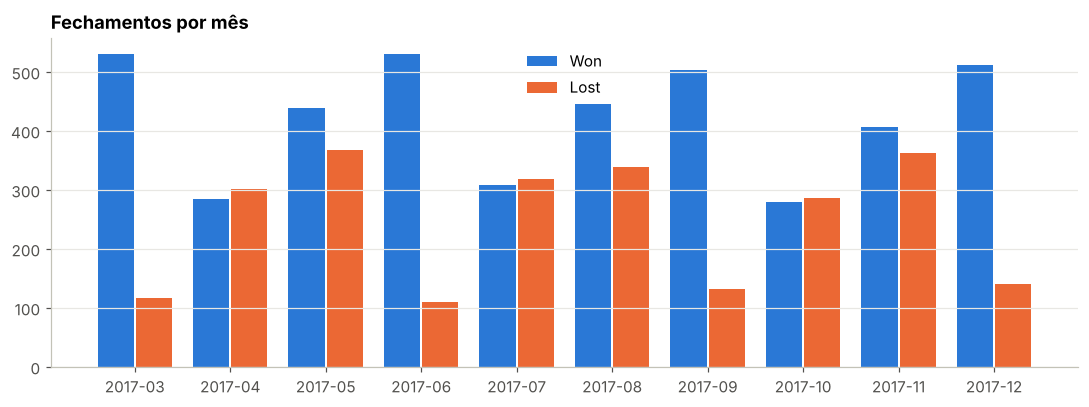

,ganhos,n,taxa
mes_do_tri,,,
1º mês,872,1779,0.490
2º mês,1290,2358,0.547
3º mês (fim do tri),2076,2574,0.807


In [24]:
fechados["mes_fech"] = fechados.close_date.dt.to_period("M")
mensal = fechados.groupby(["mes_fech", "deal_stage"]).size().unstack(fill_value=0)
mensal["taxa"] = mensal.Won / (mensal.Won + mensal.Lost)

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(mensal))
ax.bar(x - 0.2, mensal.Won, width=0.38, color=AZUL, label="Won")
ax.bar(x + 0.2, mensal.Lost, width=0.38, color=LARANJA, label="Lost")
ax.set_xticks(x, [str(m) for m in mensal.index], rotation=0)
ax.set_title("Fechamentos por mês"); ax.legend(); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

fechados["mes_do_tri"] = (fechados.close_date.dt.month - 1) % 3 + 1
taxa_por("mes_do_tri")[0][["ganhos", "n", "taxa"]].rename(index={1: "1º mês", 2: "2º mês", 3: "3º mês (fim do tri)"})

**Leitura:** há um padrão forte de fim de trimestre. No 3º mês a taxa de ganho passa de 80%; nos outros fica em torno de 50%. Tem cara de "empurrão de fechamento" (ou de artefato de como o dataset foi gerado).

**Por que não entra no score:** esse padrão depende da `close_date`, que só existe depois do fechamento. O que dá para usar é uma ideia operacional: deals vivos e maduros perto do fim do trimestre são os candidatos naturais ao empurrão. A ferramenta pode mostrar isso como contexto, não como pontuação.

O 1º trimestre de 2017 (82%) também é viés de seleção: os únicos deals fechados nele são os engajados a partir de out/2016, que fecharam rápido.

## 9. Valor dos deals

O desafio pede um score que não seja "só ordenar por valor", mas o valor precisa entrar: perder um deal de US$ 55 não é o mesmo que perder um de US$ 26 mil. Para deals abertos não existe `close_value`. Verifico se o **preço de lista** do produto é um bom substituto.

In [25]:
ganhos = fechados[fechados.ganho == 1]
razao = ganhos.close_value / ganhos.sales_price
print("close_value / preço de lista nos deals ganhos:")
print(razao.describe(percentiles=[.05, .25, .5, .75, .95]))

close_value / preço de lista nos deals ganhos:
count   4,238.000
mean        0.996
std         0.099
min         0.657
5%          0.833
25%         0.929
50%         0.998
75%         1.063
95%         1.164
max         1.342
dtype: float64


In [26]:
prod_val = (df.groupby("product")
              .agg(preco_lista=("sales_price", "first"),
                   deals_abertos=("deal_stage", lambda s: s.isin(["Prospecting", "Engaging"]).sum()))
              .sort_values("preco_lista"))
prod_val["valor_aberto"] = prod_val.preco_lista * prod_val.deals_abertos
prod_val["% do valor aberto"] = prod_val.valor_aberto / prod_val.valor_aberto.sum()
prod_val

,preco_lista,deals_abertos,valor_aberto,% do valor aberto
product,,,,
MG Special,55,428,23540,0.005
GTX Basic,550,430,236500,0.048
GTX Plus Basic,1096,332,363872,0.073
MG Advanced,3393,328,1112904,0.224
GTX Pro,4821,333,1605393,0.323
GTX Plus Pro,5482,223,1222486,0.246
GTK 500,26768,15,401520,0.081


**Leitura:** o valor fechado fica, em média, a ±10% do preço de lista (mediana 1,00). Ou seja, **o preço de lista é um ótimo proxy de valor** para deals abertos.

A amplitude entre produtos é de quase 500 vezes (US$ 55 a US$ 26.768). GTX Pro e GTX Plus Pro concentram a maior parte do valor em aberto, enquanto MG Special tem muitos deals de valor quase irrelevante. Como a chance de ganho é parecida entre produtos, **o valor é o principal diferenciador de prioridade**. O score combina valor com o sinal de tempo, que é o que varia de verdade entre os deals.

## 10. Backtest sem vazamento: o histórico prevê o resultado?

Esta é a prova decisiva. Para cada deal fechado, calculo a taxa de ganho histórica do seu vendedor, conta, produto e vendedor × produto **usando apenas deals que já tinham fechado antes do engajamento dele**. É exatamente a informação que um score teria em mãos naquele momento.

As taxas passam por um *shrinkage* bayesiano (k = 20), que puxa amostras pequenas para a média em vez de confiar em 3 de 3.

Meço com **AUC**: 0,5 é cara-ou-coroa e 1,0 é previsão perfeita. Avalio nos deals engajados a partir de abr/2017, para que todos tenham histórico.

In [27]:
def taxa_historica(hist, alvo, chaves, k=20):
    """Taxa de ganho da chave usando só deals fechados ANTES do engage_date do alvo."""
    hist = hist.sort_values("close_date")
    datas_glob = hist.close_date.values
    cum_glob = hist.ganho.cumsum().values
    n_glob = np.searchsorted(datas_glob, alvo.engage_date.values, side="left")
    base = np.where(n_glob > 0, cum_glob[np.maximum(n_glob - 1, 0)] / np.maximum(n_glob, 1), np.nan)

    grupos = {chave: (g.close_date.values, g.ganho.cumsum().values) for chave, g in hist.groupby(chaves)}
    n = np.zeros(len(alvo)); w = np.zeros(len(alvo))
    for i, (chave, data) in enumerate(zip(alvo[chaves].itertuples(index=False, name=None), alvo.engage_date.values)):
        if chave in grupos:
            datas, cum = grupos[chave]
            j = np.searchsorted(datas, data, side="left")
            n[i] = j
            w[i] = cum[j - 1] if j > 0 else 0
    return (w + k * base) / (n + k), n

features = {
    "vendedor": ["sales_agent"], "conta": ["account"], "produto": ["product"],
    "vendedor × produto": ["sales_agent", "product"], "setor": ["sector"], "manager": ["manager"],
}
bt = fechados.copy()
for nome, chaves in features.items():
    bt[f"hist_{nome}"], bt[f"n_{nome}"] = taxa_historica(fechados, bt, chaves)

teste = bt[bt.engage_date >= "2017-04-01"].copy()
print(f"Deals avaliados: {len(teste):,}  |  taxa de ganho: {teste.ganho.mean():.1%}")

Deals avaliados: 5,084  |  taxa de ganho: 60.8%


In [28]:
def auc_ic(y, s, b=500, seed=0):
    rng = np.random.default_rng(seed)
    y, s = np.asarray(y), np.asarray(s)
    pontos = roc_auc_score(y, s)
    boots = []
    for _ in range(b):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() != y[idx].max():
            boots.append(roc_auc_score(y[idx], s[idx]))
    return pontos, np.quantile(boots, 0.025), np.quantile(boots, 0.975)

res = []
for nome in features:
    a, lo, hi = auc_ic(teste.ganho, teste[f"hist_{nome}"])
    res.append({"sinal": f"taxa histórica — {nome}", "AUC": a, "IC 95% inf": lo, "IC 95% sup": hi})
auc_tab = pd.DataFrame(res).sort_values("AUC", ascending=False)
auc_tab

,sinal,AUC,IC 95% inf,IC 95% sup
0,taxa histórica — vendedor,0.482,0.466,0.498
3,taxa histórica — vendedor × produto,0.481,0.464,0.497
1,taxa histórica — conta,0.465,0.450,0.482
2,taxa histórica — produto,0.464,0.449,0.480
4,taxa histórica — setor,0.461,0.446,0.479
5,taxa histórica — manager,0.457,0.442,0.472


Agora um teste mais forte: se nenhum sinal isolado funciona, talvez **combinados num modelo de machine learning** funcionem. Treino uma regressão logística e um gradient boosting com todos os atributos categóricos e numéricos disponíveis antes do fechamento, num **split temporal**: treino com deals engajados até maio/2017 e teste com os engajados de junho em diante.

In [29]:
cat_cols = ["sales_agent", "manager", "regional_office", "product", "series", "sector", "office_location"]
num_cols = ["sales_price", "revenue", "employees", "year_established"]
X_cols = cat_cols + num_cols

treino = fechados[fechados.engage_date < "2017-06-01"]
validacao = fechados[fechados.engage_date >= "2017-06-01"]
print(f"Treino: {len(treino):,} deals  |  Teste: {len(validacao):,} deals")

prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
                          ("num", StandardScaler(), num_cols)])
modelos = {
    "Regressão logística": make_pipeline(prep, LogisticRegression(max_iter=2000, C=0.5)),
    "Gradient boosting": make_pipeline(ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)],
                                                         remainder="passthrough"),
                                       HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0)),
}
for nome, m in modelos.items():
    m.fit(treino[X_cols], treino.ganho)
    a, lo, hi = auc_ic(validacao.ganho, m.predict_proba(validacao[X_cols])[:, 1])
    auc_tab.loc[len(auc_tab)] = {"sinal": f"modelo ML — {nome}", "AUC": a, "IC 95% inf": lo, "IC 95% sup": hi}

auc_tab = auc_tab.reset_index(drop=True)
auc_tab

Treino: 2,968 deals  |  Teste: 3,743 deals


,sinal,AUC,IC 95% inf,IC 95% sup
0,taxa histórica — vendedor,0.482,0.466,0.498
1,taxa histórica — vendedor × produto,0.481,0.464,0.497
2,taxa histórica — conta,0.465,0.450,0.482
3,taxa histórica — produto,0.464,0.449,0.480
4,taxa histórica — setor,0.461,0.446,0.479
5,taxa histórica — manager,0.457,0.442,0.472
6,modelo ML — Regressão logística,0.529,0.509,0.548
7,modelo ML — Gradient boosting,0.512,0.493,0.532


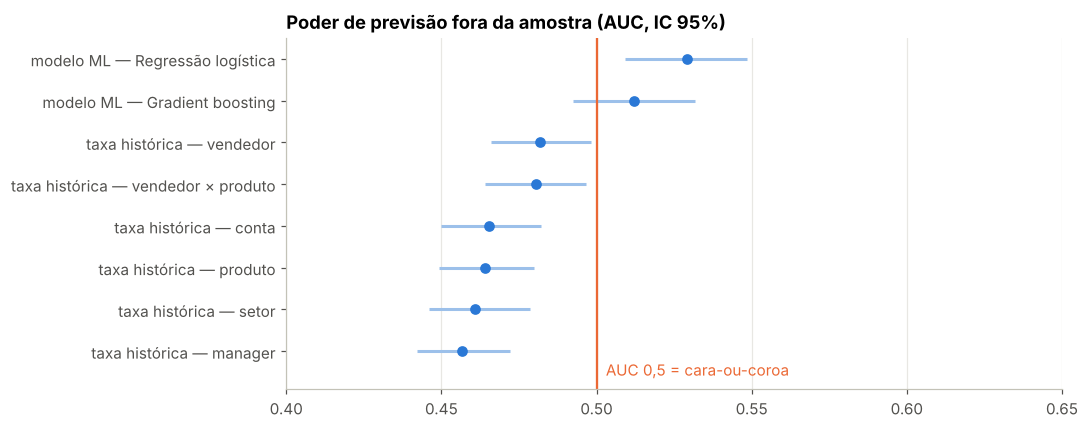

In [30]:
fig, ax = plt.subplots(figsize=(10, 4))
t = auc_tab.sort_values("AUC")
y = np.arange(len(t))
ax.errorbar(t.AUC, y, xerr=[t.AUC - t["IC 95% inf"], t["IC 95% sup"] - t.AUC], fmt="o",
            color=AZUL, ecolor="#9cc0ea", elinewidth=2, capsize=0)
ax.axvline(0.5, color=LARANJA, lw=1.5)
ax.text(0.503, -0.45, "AUC 0,5 = cara-ou-coroa", color=LARANJA, va="center")
ax.set_yticks(y, t.sinal)
ax.set_xlim(0.40, 0.65); ax.set_ylim(-0.9, len(t) - 0.5)
ax.set_title("Poder de previsão fora da amostra (AUC, IC 95%)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Leitura (o achado central):**

- **As taxas históricas não só falham em prever: o IC delas fica inteiramente abaixo de 0,5.** Quem foi bem no passado vai levemente pior em seguida. É um padrão de reversão à média, e mais um indício de que o dataset foi gerado de forma balanceada.
- **O melhor modelo de ML fica em torno de 0,53.** Estatisticamente é um pouco acima do acaso, mas não tem utilidade prática: comparando um deal ganho com um perdido, o modelo acerta qual é qual em 53% das vezes.

Um scoring baseado em "esse vendedor ou setor costuma ganhar" **pareceria inteligente no dashboard e estaria ordenando ruído.**

Isso tem uma consequência prática para o desenho da ferramenta: **ela não deve fingir saber quais deals vão fechar.** O que ela pode fazer com honestidade é:

1. usar o único sinal com base, que é a idade do deal dentro da janela histórica;
2. ponderar por **valor**;
3. separar os deals que não estão mais "vivos" pelos padrões históricos, o que libera o tempo do vendedor.

## 11. Pipeline aberto hoje (referência: 31/12/2017)

Aplico os achados ao pipeline aberto, que é onde está a decisão do vendedor na segunda-feira.

In [31]:
eng = abertos[abertos.deal_stage == "Engaging"].copy()
eng["faixa_idade"] = pd.cut(eng.idade_dias, [0, 14, 60, 90, CICLO_MAX, 200, 300, 600],
                            labels=["0–14", "15–60", "61–90", f"91–{CICLO_MAX}", f"{CICLO_MAX+1}–200", "201–300", "300+"])
faixas = eng.groupby("faixa_idade", observed=False).agg(deals=("opportunity_id", "count"), valor_lista=("sales_price", "sum"))
faixas["% deals"] = faixas.deals / faixas.deals.sum()
faixas

,deals,valor_lista,% deals
faixa_idade,,,
0–14,7,16385,0.004
15–60,50,96510,0.031
61–90,53,114756,0.033
91–138,188,465914,0.118
139–200,642,1482090,0.404
201–300,411,1076023,0.259
300+,238,640551,0.150


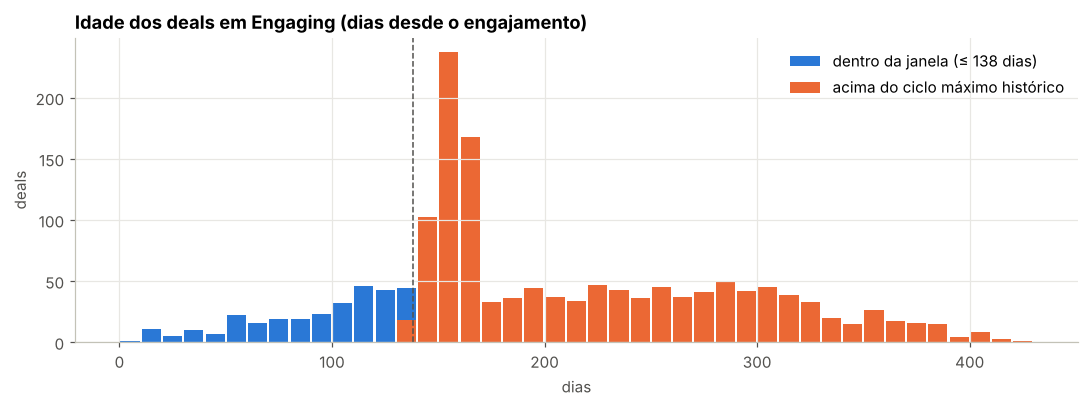

In [32]:
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.arange(0, eng.idade_dias.max() + 10, 10)
ax.hist(eng.loc[eng.idade_dias <= CICLO_MAX, "idade_dias"], bins=bins, color=AZUL, label=f"dentro da janela (≤ {CICLO_MAX} dias)", rwidth=0.9)
ax.hist(eng.loc[eng.idade_dias > CICLO_MAX, "idade_dias"], bins=bins, color=LARANJA, label=f"acima do ciclo máximo histórico", rwidth=0.9)
ax.axvline(CICLO_MAX, color=TINTA, lw=1, ls="--")
ax.set_title("Idade dos deals em Engaging (dias desde o engajamento)")
ax.set_xlabel("dias"); ax.set_ylabel("deals"); ax.legend()
plt.tight_layout(); plt.show()

In [33]:
zumbi = eng.idade_dias > CICLO_MAX
valor_total_aberto = abertos.sales_price.sum()
print(f"Engaging acima de {CICLO_MAX} dias: {zumbi.sum():,} de {len(eng):,} ({zumbi.mean():.0%})")
print(f"Valor de lista nesses deals: US$ {eng.loc[zumbi, 'sales_price'].sum():,.0f} "
      f"de US$ {valor_total_aberto:,.0f} em aberto ({eng.loc[zumbi, 'sales_price'].sum() / valor_total_aberto:.0%})")
print(f"Engaging dentro da janela: {(~zumbi).sum():,} deals, US$ {eng.loc[~zumbi, 'sales_price'].sum():,.0f}")
print(f"Prospecting (ainda sem engajamento): {(abertos.deal_stage == 'Prospecting').sum():,} deals")
print(f"Abertos sem conta: {abertos.account.isna().sum():,} de {len(abertos):,} ({abertos.account.isna().mean():.0%})")

Engaging acima de 138 dias: 1,291 de 1,589 (81%)
Valor de lista nesses deals: US$ 3,198,664 de US$ 4,966,215 em aberto (64%)
Engaging dentro da janela: 298 deals, US$ 693,565
Prospecting (ainda sem engajamento): 500 deals
Abertos sem conta: 1,425 de 2,089 (68%)


In [34]:
# Mês de engajamento dos zumbis: quando o pipeline "parou de ser atualizado"?
eng.loc[zumbi].engage_date.dt.to_period("M").value_counts().sort_index().to_frame("deals acima de 138 dias")

,deals acima de 138 dias
engage_date,
2016-11,13
2016-12,40
2017-01,65
2017-02,95
2017-03,137
2017-04,121
2017-05,134
2017-06,111
2017-07,402


In [35]:
# Visão por vendedor: carteira aberta, quanto dela está viva e quanto está parada
abertos["status"] = np.select(
    [abertos.deal_stage == "Prospecting", abertos.idade_dias > CICLO_MAX],
    ["prospecting", "acima de 138d"], default="vivo")
carteira = abertos.pivot_table(index=["manager", "sales_agent"], columns="status", values="opportunity_id",
                               aggfunc="count", fill_value=0)
carteira["total"] = carteira.sum(axis=1)
carteira["% parado"] = carteira["acima de 138d"] / carteira.total
carteira["sem conta"] = abertos.groupby(["manager", "sales_agent"]).account.apply(lambda s: s.isna().sum())
carteira["valor vivo (US$)"] = abertos[abertos.status == "vivo"].groupby(["manager", "sales_agent"]).sales_price.sum()
carteira = carteira.fillna(0).sort_values("% parado", ascending=False)
carteira.head(12)

status                            acima de 138d  prospecting  vivo  total  % parado  sem conta  valor vivo (US$)
manager       sales_agent                                                                                       
Celia Rouche  Hayden Neloms                  44            0     6     50     0.880         36        10,136.000
Cara Losch    Rosie Papadopoulos             33            0     6     39     0.846         24        23,227.000
Summer Sewald Kary Hendrixson                82            0    21    103     0.796         66        47,250.000
Cara Losch    Corliss Cosme                  63            0    18     81     0.778         54        56,886.000
Rocco Neubert Boris Faz                      44            0    13     57     0.772         39        34,180.000
Summer Sewald James Ascencio                 47            0    14     61     0.770         44        58,024.000
Celia Rouche  Vicki Laflamme                 80            0    24    104     0.769         77        51,022.000
              Elease Gluck                   39            0    12     51     0.765         33        20,659.000
              Markita Hansen                 60            0    19     79     0.759         52        32,105.000
Summer Sewald Maureen Marcano                54            0    18     72     0.750         56        40,823.000
Cara Losch    Violet Mclelland               51            0    17     68     0.750         48        12,606.000
Rocco Neubert Cassey Cress                   62            0    23     85     0.729         56        48,662.000

In [36]:
mgr = abertos.groupby("manager").agg(abertos=("opportunity_id", "count"),
                                     parados=("status", lambda s: (s == "acima de 138d").sum()),
                                     sem_conta=("account", lambda s: s.isna().sum()))
mgr["% parados"] = mgr.parados / mgr.abertos
mgr["% sem conta"] = mgr.sem_conta / mgr.abertos
mgr.sort_values("% parados", ascending=False)

,abertos,parados,sem_conta,% parados,% sem conta
manager,,,,,
Cara Losch,219,169,154,0.772,0.703
Celia Rouche,334,257,232,0.769,0.695
Summer Sewald,414,305,286,0.737,0.691
Rocco Neubert,214,157,142,0.734,0.664
Dustin Brinkmann,397,190,272,0.479,0.685
Melvin Marxen,511,213,339,0.417,0.663


Dois managers, Dustin Brinkmann e Melvin Marxen, têm cerca de metade da taxa de deals parados dos demais. Os dois são do escritório **Central**. Antes de concluir que o Central é mais disciplinado, abro por região.

In [37]:
pd.crosstab(df.regional_office, df.deal_stage)

deal_stage,Engaging,Lost,Prospecting,Won
regional_office,,,,
Central,408,975,500,1629
East,433,687,0,1171
West,748,811,0,1438


In [38]:
reg = eng.assign(parado=zumbi).groupby("regional_office").agg(
    engaging=("opportunity_id", "count"), pct_parado=("parado", "mean"),
    idade_mediana=("idade_dias", "median"), engajados_jul_ago=("engage_date", lambda s: s.between("2017-07-01", "2017-08-31").sum()))
reg["% engajados jul–ago"] = reg.engajados_jul_ago / reg.engaging
reg

,engaging,pct_parado,idade_mediana,engajados_jul_ago,% engajados jul–ago
regional_office,,,,,
Central,408,0.988,157.000,408,1.000
East,433,0.753,212.000,99,0.229
West,748,0.751,219.500,149,0.199


In [39]:
eng.assign(mes=eng.engage_date.dt.to_period("M")).pivot_table(index="mes", columns="regional_office",
                                                               values="opportunity_id", aggfunc="count", fill_value=0)

regional_office,Central,East,West
mes,,,
2016-11,0,3,10
2016-12,0,15,25
2017-01,0,24,41
2017-02,0,27,68
2017-03,0,57,80
2017-04,0,41,80
2017-05,0,48,86
2017-06,0,42,69
2017-07,287,49,66


**A hipótese inicial estava errada, e o achado real é mais importante:**

- **Todos os 500 deals em Prospecting são do Central.** Isso dilui o % de parados dos dois managers; não é disciplina.
- **99% do Engaging do Central está parado, e 100% dele foi engajado em jul–ago/2017**, concentrado em cerca de 4 semanas. O mesmo time continuou fechando deals engajados em set–out normalmente. Ou seja, o time está ativo, mas um bloco inteiro de deals ficou para trás.
- Isso tem cara de **importação em lote ou campanha que nunca foi trabalhada até o fim**, e não de deals vivos. Em um caso real, a primeira pergunta para a Head de RevOps seria: "o que aconteceu com o Central em julho?".

Na ferramenta, isso reforça que a fila **"Requalificar ou encerrar"** precisa de filtro por região e manager. Limpar esse bloco é uma decisão de gestão, não de vendedor.

**Leitura:**

- **A maior parte do Engaging está acima do ciclo máximo histórico.** Esses deals concentram cerca de dois terços do valor em aberto. Boa parte veio do pico de engajamentos de jul–ago/2017 e nunca foi atualizada. É exatamente o "tempo em deals que não vão fechar" que a Head de RevOps descreveu, só que agora medido.
- **Só uma fração pequena do Engaging está viva** pela janela histórica. Essa é a lista de foco real do time.
- **A falta de conta é generalizada** (66% a 70% em todos os managers): não é problema de um vendedor só, é de processo de cadastro.

## 12. Robustez: descritiva, outliers, possíveis erros, correlações e regressão

As seções anteriores responderam às perguntas de negócio. Esta seção revisita os dados com o olhar de um auditor estatístico:

1. **Estatística descritiva** completa: tendência central, dispersão, assimetria e curtose.
2. **Outliers**: são erros ou valores legítimos?
3. **Possíveis erros de registro** que passaram pelas checagens da seção 2.
4. **Viés de censura**: o corte de 138 dias é real ou é efeito de o dataset terminar em dez/2017?
5. **Correlações** entre todas as variáveis, numéricas e categóricas.
6. **Regressão inferencial** com coeficientes interpretáveis: alguma variável explica ganho, ciclo ou desconto?

### 12.1 Estatística descritiva

In [40]:
import statsmodels.formula.api as smf

def descritiva(d):
    t = d.describe().T
    t["cv"] = t["std"] / t["mean"]
    t["assimetria"] = d.skew()
    t["curtose"] = d.kurt()
    return t

print("Contas (85)")
descritiva(accounts[["year_established", "revenue", "employees"]])

Contas (85)


,count,mean,std,min,25%,50%,75%,max,cv,assimetria,curtose
year_established,85.000,"1,996.106",8.865,"1,979.000","1,989.000","1,996.000","2,002.000","2,017.000",0.004,0.190,-0.661
revenue,85.000,"1,994.633","2,169.491",4.540,497.110,"1,223.720","2,741.370","11,698.030",1.088,2.003,4.833
employees,85.000,"4,660.824","5,715.601",9.000,"1,179.000","2,769.000","5,595.000","34,288.000",1.226,2.570,8.674


In [41]:
fechados["razao_preco"] = np.where(fechados.ganho == 1, fechados.close_value / fechados.sales_price, np.nan)
print("Deals fechados (6.711)")
descritiva(fechados[["ciclo_dias", "sales_price", "close_value", "razao_preco"]])

Deals fechados (6.711)


,count,mean,std,min,25%,50%,75%,max,cv,assimetria,curtose
ciclo_dias,"6,711.000",47.985,41.058,1.000,8.000,45.000,85.000,138.000,0.856,0.306,-1.425
sales_price,"6,711.000","2,379.668","2,535.519",55.000,550.000,"1,096.000","4,821.000","26,768.000",1.065,3.442,29.516
close_value,"6,711.000","1,490.916","2,320.671",0.000,0.000,472.000,"3,225.000","30,288.000",1.557,3.573,30.758
razao_preco,"4,238.000",0.996,0.099,0.657,0.929,0.998,1.063,1.342,0.099,-0.008,-0.044


In [42]:
# Categóricas: cardinalidade e concentração
cat_resumo = []
for col in ["sales_agent", "manager", "regional_office", "product", "series", "account", "sector", "office_location"]:
    vc = df[col].value_counts(dropna=True)
    cat_resumo.append({"variável": col, "categorias": len(vc), "mais frequente": vc.index[0],
                       "freq. máx": vc.iloc[0], "freq. mín": vc.iloc[-1], "% da mais frequente": vc.iloc[0] / vc.sum(),
                       "nulos": df[col].isna().sum()})
pd.DataFrame(cat_resumo).set_index("variável")

,categorias,mais frequente,freq. máx,freq. mín,% da mais frequente,nulos
variável,,,,,,
sales_agent,30,Darcel Schlecht,747,110,0.085,0
manager,6,Melvin Marxen,1929,964,0.219,0
regional_office,3,Central,3512,2291,0.399,0
product,7,GTX Basic,1866,40,0.212,0
series,3,GTX,5697,40,0.647,0
account,85,Hottechi,200,51,0.027,1425
sector,10,retail,1397,311,0.189,1425
office_location,15,United States,6120,52,0.830,1425


**Leitura:**

- **Receita e funcionários das contas são muito assimétricos à direita** (assimetria 2,0 e 2,6; curtose 4,8 e 8,7). Isso pede transformação logarítmica em qualquer modelo, e por isso as regressões abaixo usam `log`.
- **O ciclo não tem cauda:** máximo de 138, curtose negativa. É uma distribuição limitada, coerente com o teto da seção 7.
- **A razão entre preço fechado e preço de lista** tem média 1,00 e desvio 0,10.
- **Preço de lista e valor fechado também são muito assimétricos** (curtose ≈ 30). Isso acontece por causa do GTK 500, que custa cerca de 10 vezes o segundo produto mais caro. É um valor legítimo, não um erro.
- **Os Estados Unidos concentram 83% dos deals com conta.** As comparações por país têm pouca amostra fora dos EUA.
- O vendedor mais frequente, Darcel Schlecht, tem quase 3 vezes a mediana de deals. Isso é avaliado abaixo.

### 12.2 Outliers

Uso dois critérios: **IQR** (abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR) e **escore z > 3**. Detectar o outlier é a parte fácil. A pergunta que importa é se ele é um **erro** (corrigir ou excluir) ou um **valor legítimo** (manter).

In [43]:
def outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]

acc_l = accounts.replace({"sector": {"technolgy": "technology"}})
acc_l["receita_por_func_mil"] = acc_l.revenue * 1e6 / acc_l.employees / 1e3
out_idx = outliers_iqr(acc_l.revenue).index.union(outliers_iqr(acc_l.employees).index)
print(f"Contas outlier em receita ou funcionários (IQR): {len(out_idx)}")
print(f"Correlação de Spearman receita x funcionários: {stats.spearmanr(acc_l.revenue, acc_l.employees)[0]:.3f}")
acc_l.loc[out_idx, ["account", "sector", "revenue", "employees", "receita_por_func_mil"]].sort_values("revenue", ascending=False)

Contas outlier em receita ou funcionários (IQR): 8
Correlação de Spearman receita x funcionários: 0.959


,account,sector,revenue,employees,receita_por_func_mil
41,Kan-code,software,"11,698.030",34288,341.170
35,Hottechi,technology,"8,170.380",16499,495.205
43,Konex,technology,"7,708.380",13756,560.365
76,Xx-holding,finance,"7,537.240",20293,371.421
36,Initech,telecommunications,"6,395.050",20275,315.416
60,Scotfind,software,"6,354.870",16780,378.717
25,Ganjaflex,retail,"5,158.710",17479,295.138
83,Zotware,software,"4,478.470",13809,324.315


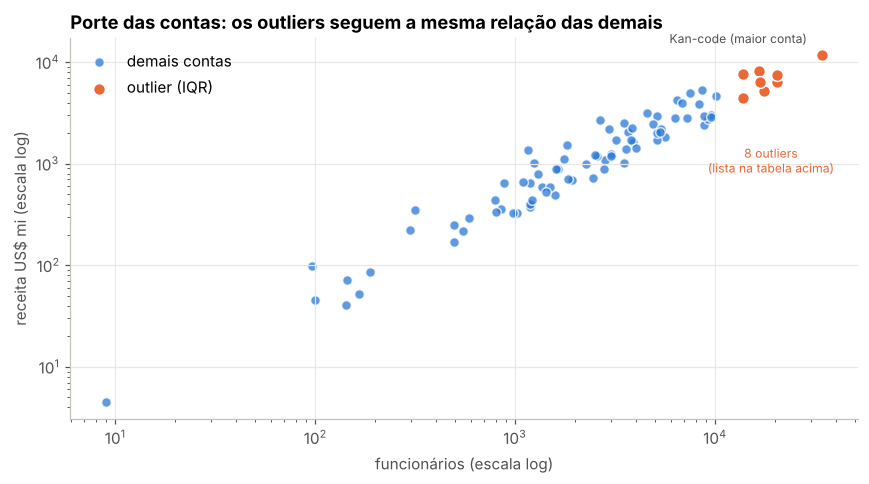

Receita por funcionário (US$ mil):
count      85.000
mean      486.000
std       190.100
min       273.100
25%       344.000
50%       433.100
75%       561.400
max     1,181.800
Name: receita_por_func_mil, dtype: float64


In [44]:
fig, ax = plt.subplots(figsize=(8, 4.5))
normais = acc_l.drop(out_idx)
ax.scatter(normais.employees, normais.revenue, s=40, color=AZUL, alpha=0.75, label="demais contas", edgecolor="white", linewidth=1)
ax.scatter(acc_l.loc[out_idx, "employees"], acc_l.loc[out_idx, "revenue"], s=60, color=LARANJA,
           label="outlier (IQR)", edgecolor="white", linewidth=1)
for nome in ["Kan-code"]:
    r = acc_l.set_index("account").loc[nome]
    ax.annotate(f"{nome} (maior conta)", (r.employees, r.revenue), xytext=(-10, 8), textcoords="offset points",
                fontsize=8, color=TINTA, ha="right")
ax.annotate("8 outliers\n(lista na tabela acima)", xy=(19000, 1500), fontsize=8, color=LARANJA, ha="center", va="top")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("funcionários (escala log)"); ax.set_ylabel("receita US$ mi (escala log)")
ax.set_title("Porte das contas: os outliers seguem a mesma relação das demais"); ax.legend()
plt.tight_layout(); plt.show()
print("Receita por funcionário (US$ mil):")
print(acc_l.receita_por_func_mil.describe().round(1))

**Leitura (contas):** as 8 contas outlier são **grandes, não erradas**. Elas ficam exatamente sobre a reta receita × funcionários (Spearman 0,96), e a receita por funcionário de todas as contas fica numa faixa plausível, entre US$ 273 mil e US$ 1,2 milhão. **Mantidas.**

Receita e funcionários medem a mesma coisa (porte). Colocar as duas no mesmo modelo gera multicolinearidade.

Deals ganhos com |z| > 3 dentro do produto: 11
Esperado se a razão fosse normal: 11.4
Teste KS de normalidade da razão padronizada: p = 0.57
Vendidos acima de 120% do preço de lista: 80  |  abaixo de 80%: 92


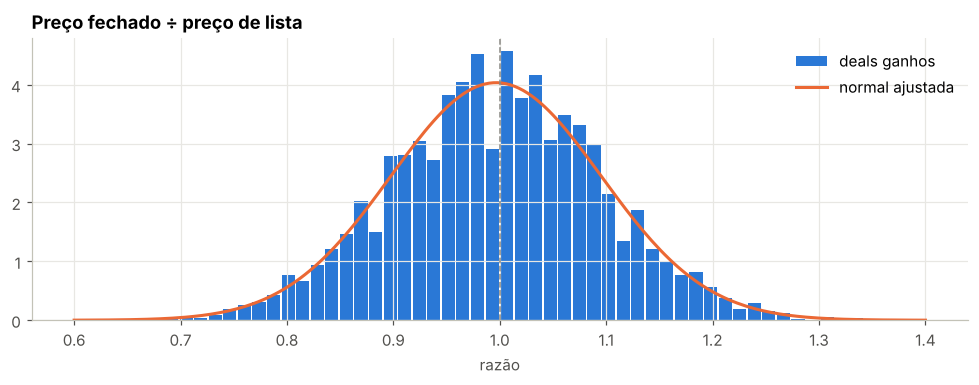

In [45]:
# Desconto/ágio sobre o preço de lista (só ganhos)
g = fechados[fechados.ganho == 1].copy()
g["z_no_produto"] = g.groupby("product").razao_preco.transform(lambda s: (s - s.mean()) / s.std())
n_z3 = (g.z_no_produto.abs() > 3).sum()
esperado = len(g) * 2 * stats.norm.sf(3)
ks = stats.kstest(g.z_no_produto, "norm")
print(f"Deals ganhos com |z| > 3 dentro do produto: {n_z3}")
print(f"Esperado se a razão fosse normal: {esperado:.1f}")
print(f"Teste KS de normalidade da razão padronizada: p = {ks.pvalue:.2f}")
print(f"Vendidos acima de 120% do preço de lista: {(g.razao_preco > 1.2).sum()}  |  abaixo de 80%: {(g.razao_preco < 0.8).sum()}")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(g.razao_preco, bins=50, color=AZUL, rwidth=0.9, density=True, label="deals ganhos")
xs = np.linspace(0.6, 1.4, 200)
ax.plot(xs, stats.norm.pdf(xs, g.razao_preco.mean(), g.razao_preco.std()), color=LARANJA, lw=2, label="normal ajustada")
ax.axvline(1, color=CINZA, ls="--", lw=1)
ax.set_title("Preço fechado ÷ preço de lista"); ax.set_xlabel("razão"); ax.legend()
plt.tight_layout(); plt.show()

**Leitura (preço):** os 11 deals com |z| > 3 são **exatamente o número esperado** se a razão fosse uma variável normal pura (≈ 11). O teste KS também não rejeita a normalidade. Ou seja, esses "outliers" não são erros, são a cauda natural de um ruído normal em torno do preço de lista.

**Do ponto de vista de negócio**, porém, há algo a perguntar: 80 deals ganhos (1,9%) foram vendidos **acima de 120% do preço de lista**, chegando a +34%, e 92 abaixo de 80%. Em uma empresa real, isso seria um ponto para investigar (ágio, venda com serviços, erro de digitação?).

In [46]:
# Volume: deals por conta e por vendedor
dpa = df.groupby("account").size()
dpv = df.groupby("sales_agent").size()
print("Contas com volume outlier:", outliers_iqr(dpa).to_dict())
print("Vendedores com volume outlier:", outliers_iqr(dpv).to_dict(), f"| mediana: {dpv.median():.0f}")
porte = dpa.rename("deals").to_frame().join(accounts.set_index("account"))
taxa_conta = fechados.groupby("account").ganho.mean()
print(f"Spearman deals por conta x receita: {stats.spearmanr(porte.deals, porte.revenue)[0]:.2f}")
print(f"Spearman taxa de ganho da conta x deals da conta: {stats.spearmanr(taxa_conta, dpa.loc[taxa_conta.index])[0]:.2f}")
print(f"Taxa de ganho de Darcel Schlecht: {fechados[fechados.sales_agent == 'Darcel Schlecht'].ganho.mean():.1%} (geral {taxa_geral:.1%})")

Contas com volume outlier: {'Condax': 170, 'Hottechi': 200, 'Kan-code': 196, 'Konex': 178}
Vendedores com volume outlier: {'Darcel Schlecht': 747} | mediana: 278
Spearman deals por conta x receita: 0.59
Spearman taxa de ganho da conta x deals da conta: -0.01
Taxa de ganho de Darcel Schlecht: 63.1% (geral 63.2%)


**Leitura (volume):**

- **As contas grandes geram mais deals** (Spearman 0,59 com receita), mas **não ganham mais**: a correlação da taxa de ganho com o volume é zero. Porte define *quantas* oportunidades aparecem, não *quais* fecham.
- **Darcel Schlecht tem 747 deals**, 2,7 vezes a mediana, com taxa de ganho igual à média. Não é erro, é uma carteira grande, e ele também tem a maior carteira aberta (194 deals). Na ferramenta, é o vendedor que mais ganha com uma fila priorizada.

### 12.3 Possíveis erros de registro

Checagens adicionais de plausibilidade, além das regras da seção 2.

In [47]:
# (a) deals antes da fundação da empresa
prim = df.dropna(subset=["account"]).groupby("account").agg(fundacao=("year_established", "first"),
                                                            primeiro_deal=("engage_date", "min"))
print("(a) Contas com deal antes do ano de fundação:")
print(prim[prim.primeiro_deal.dt.year < prim.fundacao])

# (b) duplicatas lógicas: mesmo vendedor + produto + conta + data de engajamento
chave = ["sales_agent", "product", "account", "engage_date"]
dup = df[df.account.notna() & df.duplicated(chave, keep=False)]
combos = dup.groupby(chave).deal_stage.agg(lambda s: " / ".join(sorted(s)))
print(f"\n(b) Duplicatas lógicas: {len(dup)} deals em {len(combos)} grupos")
print(combos.value_counts().to_string())

# (c) deals fechados em 1 dia
print(f"\n(c) Fechados em até 1 dia: {(fechados.ciclo_dias <= 1).sum()} — taxa de ganho {fechados.loc[fechados.ciclo_dias <= 1, 'ganho'].mean():.1%}")

# (d) atividade por dia da semana
dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
print("\n(d) Engajamentos por dia da semana:",
      dict(zip(dias, df.engage_date.dt.dayofweek.value_counts().sort_index().astype(int).tolist())))

(a) Contas com deal antes do ano de fundação:


         fundacao primeiro_deal
account                        
Condax  2,017.000    2016-11-27

(b) Duplicatas lógicas: 64 deals em 27 grupos
deal_stage
Lost / Won             13
Lost / Lost             9
Won / Won               3
Engaging / Lost         1
Engaging / Engaging     1

(c) Fechados em até 1 dia: 301 — taxa de ganho 52.5%

(d) Engajamentos por dia da semana: {'seg': 1186, 'ter': 1161, 'qua': 1190, 'qui': 1211, 'sex': 1166, 'sáb': 1153, 'dom': 1233}


**Possíveis erros encontrados:**

| # | Achado | Diagnóstico | Impacto | Tratamento |
|---|---|---|---|---|
| a | **Condax** tem `year_established = 2017`, mas deals desde nov/2016 | **Erro de cadastro** (ano de fundação errado ou conta renomeada) | Baixo: idade da empresa não entra no score | Sinalizar; não usar idade da empresa |
| b | **27 grupos** (64 deals) com mesmo vendedor, produto, conta e data; em 13 deles, um registro é Won e outro Lost | **Provável duplicidade** de lançamento, ou várias unidades registradas separadamente | Baixo: 0,7% dos deals | Manter e sinalizar; no app, mostrar como "possível duplicata" |
| c | 301 deals fechados em 1 dia | Plausível (venda rápida), taxa de ganho de 52% | Já capturado pela curva de tempo | Manter |
| d | Engajamentos distribuídos igualmente entre os 7 dias, **inclusive sábado e domingo** | Implausível para vendas B2B. **Forte indício de dados sintéticos** | Explica por que quase nada prevê o resultado | Documentar como limitação |

### 12.4 Viés de censura: o teto de 138 dias é real?

Um risco sério: o dataset termina em 31/12/2017. Deals engajados em outubro só tiveram 3 meses para fechar, então o ciclo deles **não pode** ser longo. Se o teto de 138 dias fosse só isso, ele seria um artefato.

O teste é olhar **as coortes antigas**, que tiveram muito mais que 138 dias de observação. Se a regra for real, elas também nunca fecham depois de 138 dias.

In [48]:
e = df[df.engage_date.notna()].copy()
e["coorte"] = e.engage_date.dt.to_period("M")
e["ciclo"] = (e.close_date - e.engage_date).dt.days
coortes = e.groupby("coorte").agg(deals=("opportunity_id", "count"), fechados=("close_date", lambda s: s.notna().sum()),
                                  ciclo_max=("ciclo", "max"), ciclo_p90=("ciclo", lambda s: s.quantile(0.9)))
coortes["dias_observados"] = [(DATA_REF - p.start_time).days for p in coortes.index]
coortes["% ainda aberto"] = 1 - coortes.fechados / coortes.deals
coortes

,deals,fechados,ciclo_max,ciclo_p90,dias_observados,% ainda aberto
coorte,,,,,,
2016-10,7,7,137.000,135.800,456,0.000
2016-11,115,102,138.000,126.000,425,0.113
2016-12,236,196,119.000,106.000,395,0.169
2017-01,312,247,137.000,121.000,364,0.208
2017-02,515,420,137.000,120.000,333,0.184
2017-03,792,655,121.000,96.000,305,0.173
2017-04,874,753,132.000,83.000,274,0.138
2017-05,722,588,136.000,113.000,244,0.186
2017-06,792,681,124.000,96.000,213,0.140


In [49]:
antigas = coortes[coortes.dias_observados > 200]
print(f"Coortes com mais de 200 dias de observação: {len(antigas)} ({antigas.deals.sum():,} deals)")
print(f"Maior ciclo entre elas: {antigas.ciclo_max.max():.0f} dias")
print(f"Ainda abertas nessas coortes: {(antigas.deals - antigas.fechados).sum():,} deals")
print(f"Correlação de Spearman mês de engajamento x ciclo: {stats.spearmanr(fechados.engage_date.dt.month, fechados.ciclo_dias)[0]:.3f}")

Coortes com mais de 200 dias de observação: 9 (4,365 deals)
Maior ciclo entre elas: 138 dias
Ainda abertas nessas coortes: 716 deals
Correlação de Spearman mês de engajamento x ciclo: -0.156


**Leitura:** **a regra dos 138 dias resiste ao teste de censura.** As coortes de nov/2016 a jun/2017 tiveram entre 7 e 14 meses para fechar, e nenhum deal delas fechou depois de 138 dias. Mesmo assim, de 11% a 21% de cada uma continua aberta. São exatamente os deals parados.

A censura **existe** nas coortes recentes: out–dez/2017 têm ciclo máximo de 90, 58 e 24 dias, e há uma correlação negativa (−0,16) entre mês de engajamento e ciclo. Mas ela afeta só a parte final da curva, não o teto.

**Implicação para a curva da seção 7:** ela é calculada só com deals já fechados, então as coortes recentes puxam levemente para baixo a estimativa nos ciclos longos. Com dados reais e contínuos, o correto é usar o estimador de **Kaplan-Meier**, que trata os deals abertos como observações censuradas.

### 12.5 Correlações entre variáveis

- **Numéricas:** correlação de **Spearman**, que é robusta a outliers e a relações não lineares.
- **Categóricas:** **V de Cramér**, que vai de 0 (independentes) a 1 (uma determina a outra).

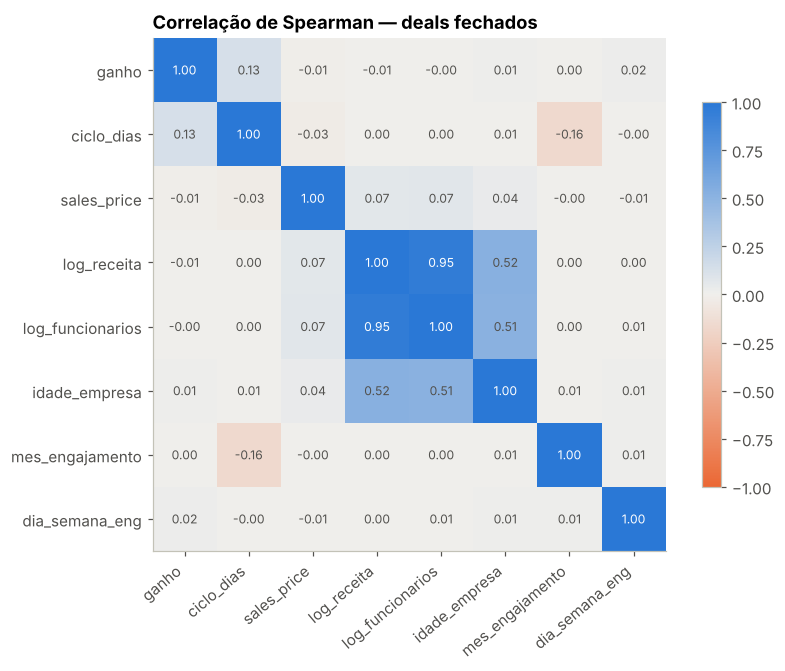

In [50]:
from matplotlib.colors import LinearSegmentedColormap
fc = fechados.copy()
fc["log_receita"] = np.log(fc.revenue)
fc["log_funcionarios"] = np.log(fc.employees)
fc["idade_empresa"] = 2017 - fc.year_established
fc["mes_engajamento"] = fc.engage_date.dt.month
fc["dia_semana_eng"] = fc.engage_date.dt.dayofweek
num = ["ganho", "ciclo_dias", "sales_price", "log_receita", "log_funcionarios", "idade_empresa", "mes_engajamento", "dia_semana_eng"]
corr = fc[num].corr("spearman")

div = LinearSegmentedColormap.from_list("div", [LARANJA, "#f0efec", AZUL])
fig, ax = plt.subplots(figsize=(8, 6.2))
im = ax.imshow(corr, cmap=div, vmin=-1, vmax=1)
ax.set_xticks(range(len(num)), num, rotation=40, ha="right"); ax.set_yticks(range(len(num)), num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else TINTA)
ax.grid(False); ax.set_title("Correlação de Spearman — deals fechados")
fig.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout(); plt.show()

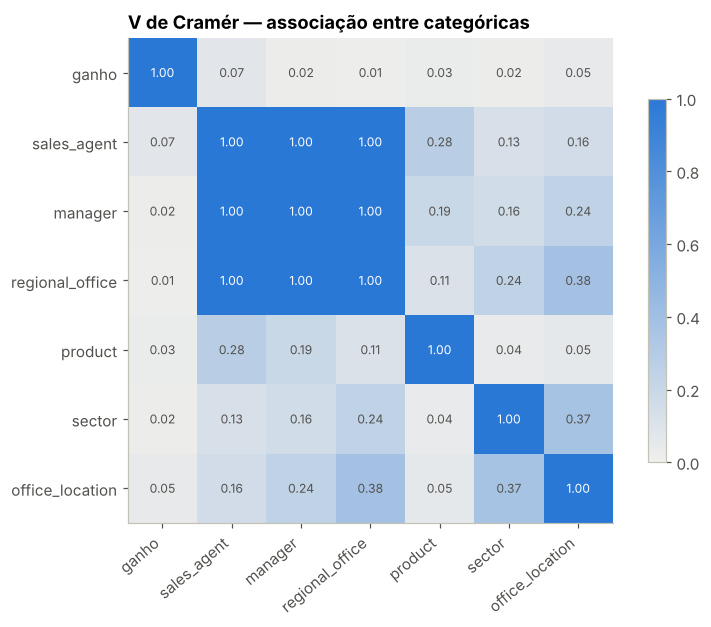

In [51]:
def cramers_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(t)[0]
    return np.sqrt(chi2 / t.values.sum() / (min(t.shape) - 1))

cats = ["ganho", "sales_agent", "manager", "regional_office", "product", "sector", "office_location"]
cv = pd.DataFrame([[cramers_v(fechados[a], fechados[b]) for b in cats] for a in cats], index=cats, columns=cats)

seq = LinearSegmentedColormap.from_list("seq", ["#f0efec", AZUL])
fig, ax = plt.subplots(figsize=(7.5, 5.8))
im = ax.imshow(cv, cmap=seq, vmin=0, vmax=1)
ax.set_xticks(range(len(cats)), cats, rotation=40, ha="right"); ax.set_yticks(range(len(cats)), cats)
for i in range(len(cats)):
    for j in range(len(cats)):
        ax.text(j, i, f"{cv.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if cv.iloc[i, j] > 0.6 else TINTA)
ax.grid(False); ax.set_title("V de Cramér — associação entre categóricas")
fig.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout(); plt.show()

In [52]:
mix = pd.crosstab(df.sales_agent, df["product"])
print("Vendedores que já tiveram deal de GTK 500:", (mix["GTK 500"] > 0).sum(), "de", len(mix))
mix["GTK 500"][mix["GTK 500"] > 0].sort_values(ascending=False).to_frame("deals GTK 500")

Vendedores que já tiveram deal de GTK 500: 6 de 30


,deals GTK 500
sales_agent,
Elease Gluck,19
Markita Hansen,10
Rosalina Dieter,8
Corliss Cosme,1
Darcel Schlecht,1
Marty Freudenburg,1


**Leitura:**

- **`ganho` não se correlaciona com nenhuma variável disponível antes do fechamento.** Todas ficam abaixo de |0,02|, e o V de Cramér com as categóricas é no máximo 0,07. A única correlação é com `ciclo_dias` (0,13), que só existe depois do fechamento.
- **Vendedor, manager e região têm V = 1,00 entre si.** É uma hierarquia: cada vendedor pertence a um único manager, e cada manager a uma única região. **Não podem entrar juntos numa regressão**, porque haveria colinearidade perfeita.
- **log_receita × log_funcionários = 0,95.** Usar só um dos dois.
- **Produto × vendedor (V = 0,28):** só 6 vendedores já tiveram deal de GTK 500, o produto de US$ 26 mil, e dois concentram 29 dos 40. É uma especialização que vale mostrar na ferramenta como contexto.
- **Mês de engajamento × ciclo (−0,16):** é o efeito de censura da seção 12.4, não uma relação real.
- **Dia da semana:** nenhuma relação com nada, o que é coerente com dados gerados artificialmente.

### 12.6 Regressão inferencial

O backtest da seção 10 mediu **previsão**. Aqui a pergunta é de **inferência**: existe alguma relação estatisticamente significativa, mesmo que pequena, e qual é o tamanho dela? Uso `statsmodels`, que dá coeficientes, erros-padrão, p-valores e testes globais.

Rodo três modelos, cada um com uma variável dependente diferente:

| Modelo | Variável dependente | Pergunta |
|---|---|---|
| Logística | `ganho` (0/1) | O que muda a chance de ganhar? |
| OLS | `ciclo_dias` | O que faz um deal demorar mais? |
| OLS | `razao_preco` (só ganhos) | O que explica desconto ou ágio? |

Por causa da colinearidade vista em 12.5, entram **região** (não manager nem vendedor) e **log_receita** (não funcionários) no mesmo modelo. Vendedor é testado num modelo separado.

In [53]:
fr = fechados.assign(log_receita=np.log(fechados.revenue), idade_empresa=2017 - fechados.year_established,
                     subsidiaria=fechados.subsidiary_of.notna().astype(int))
nulo = smf.logit("ganho ~ 1", fr).fit(disp=0)

def teste_lr(modelo, nulo=nulo):
    lr = 2 * (modelo.llf - nulo.llf)
    return lr, modelo.df_model, stats.chi2.sf(lr, modelo.df_model)

logit_attr = smf.logit("ganho ~ C(product) + C(sector) + C(regional_office) + log_receita + idade_empresa + subsidiaria", fr).fit(disp=0)
coefs = logit_attr.summary2().tables[1]
coefs["odds ratio"] = np.exp(coefs["Coef."])
coefs[["Coef.", "odds ratio", "Std.Err.", "P>|z|", "[0.025", "0.975]"]].round(3)

,Coef.,odds ratio,Std.Err.,P>|z|,[0.025,0.975]
Intercept,0.437,1.549,0.455,0.337,-0.455,1.329
C(product)[T.GTX Basic],0.183,1.200,0.414,0.659,-0.629,0.995
C(product)[T.GTX Plus Basic],0.119,1.126,0.416,0.775,-0.696,0.934
C(product)[T.GTX Plus Pro],0.214,1.238,0.418,0.609,-0.606,1.033
C(product)[T.GTX Pro],0.178,1.195,0.416,0.668,-0.637,0.993
C(product)[T.MG Advanced],0.047,1.048,0.415,0.911,-0.768,0.861
C(product)[T.MG Special],0.232,1.261,0.416,0.576,-0.582,1.047
C(sector)[T.entertainment],0.108,1.114,0.162,0.505,-0.210,0.426
C(sector)[T.finance],-0.003,0.997,0.152,0.986,-0.300,0.295
C(sector)[T.marketing],0.138,1.148,0.152,0.363,-0.160,0.436


In [54]:
logit_vend = smf.logit("ganho ~ C(sales_agent)", fr).fit(disp=0)
logit_ciclo = smf.logit("ganho ~ ciclo_dias + I(ciclo_dias**2)", fr).fit(disp=0)
logit_cedo = smf.logit("ganho ~ I(ciclo_dias <= 14)", fr).fit(disp=0)
or_cedo = np.exp(logit_cedo.params.iloc[1]); ic_cedo = np.exp(logit_cedo.conf_int().iloc[1])
print(f"Fechar em até 14 dias: odds ratio = {or_cedo:.2f} (IC 95% {ic_cedo[0]:.2f}–{ic_cedo[1]:.2f}), p = {logit_cedo.pvalues.iloc[1]:.1e}")
print("Coeficientes do ciclo (com termo quadrático):")
logit_ciclo.summary2().tables[1].round(5)

Fechar em até 14 dias: odds ratio = 0.57 (IC 95% 0.51–0.63), p = 4.5e-28
Coeficientes do ciclo (com termo quadrático):


,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,0.197,0.046,4.261,0.000,0.106,0.287
ciclo_dias,0.011,0.002,4.456,0.000,0.006,0.016
I(ciclo_dias ** 2),-0.000,0.000,-2.015,0.044,-0.000,-0.000


In [55]:
ols_ciclo = smf.ols("ciclo_dias ~ C(deal_stage) + C(product) + C(sector) + C(regional_office) + log_receita", fr).fit()
ols_ciclo_vend = smf.ols("ciclo_dias ~ C(sales_agent)", fr).fit()
fg = fr[fr.ganho == 1].assign(fim_tri=lambda d: (d.close_date.dt.month % 3 == 0).astype(int))
ols_preco = smf.ols("razao_preco ~ C(product) + C(sector) + C(regional_office) + log_receita + ciclo_dias + fim_tri", fg).fit()
ols_preco_vend = smf.ols("razao_preco ~ C(sales_agent)", fg).fit()

print("Variáveis significativas (p < 0,05) no modelo de ciclo:")
print(ols_ciclo.summary2().tables[1].loc[lambda t: t["P>|t|"] < 0.05, ["Coef.", "P>|t|", "[0.025", "0.975]"]].round(3))

Variáveis significativas (p < 0,05) no modelo de ciclo:
                      Coef.  P>|t|  [0.025  0.975]
Intercept            49.733  0.000  31.974  67.492
C(deal_stage)[T.Won] 10.319  0.000   8.296  12.343


In [56]:
linhas = []
for nome, m, dep in [
    ("Logística — produto, setor, região, porte, idade, subsidiária", logit_attr, "ganho"),
    ("Logística — vendedor", logit_vend, "ganho"),
    ("Logística — ciclo + ciclo²  (pós-fechamento)", logit_ciclo, "ganho"),
]:
    lr, gl, p = teste_lr(m)
    linhas.append({"modelo": nome, "dependente": dep, "ajuste": f"pseudo-R² = {m.prsquared:.4f}", "teste global": f"LR χ²({gl:.0f}) = {lr:.1f}", "p global": p})
for nome, m, dep in [
    ("OLS — estágio, produto, setor, região, porte", ols_ciclo, "ciclo_dias"),
    ("OLS — vendedor", ols_ciclo_vend, "ciclo_dias"),
    ("OLS — produto, setor, região, porte, ciclo, fim de tri", ols_preco, "razao_preco"),
    ("OLS — vendedor", ols_preco_vend, "razao_preco"),
]:
    linhas.append({"modelo": nome, "dependente": dep, "ajuste": f"R² = {m.rsquared:.4f}", "teste global": f"F = {m.fvalue:.2f}", "p global": m.f_pvalue})
resumo_reg = pd.DataFrame(linhas).set_index("modelo")
resumo_reg["p global"] = resumo_reg["p global"].map(lambda v: f"{v:.3f}" if v >= 0.001 else "< 0,001")
resumo_reg

,dependente,ajuste,teste global,p global
modelo,,,,
"Logística — produto, setor, região, porte, idade, subsidiária",ganho,pseudo-R² = 0.0016,LR χ²(20) = 14.1,0.825
Logística — vendedor,ganho,pseudo-R² = 0.0038,LR χ²(29) = 33.3,0.264
Logística — ciclo + ciclo² (pós-fechamento),ganho,pseudo-R² = 0.0117,LR χ²(2) = 103.5,"< 0,001"
"OLS — estágio, produto, setor, região, porte",ciclo_dias,R² = 0.0174,F = 6.24,"< 0,001"
OLS — vendedor,ciclo_dias,R² = 0.0059,F = 1.37,0.090
"OLS — produto, setor, região, porte, ciclo, fim de tri",razao_preco,R² = 0.0065,F = 1.38,0.122
OLS — vendedor,razao_preco,R² = 0.0063,F = 0.92,0.588


**Leitura:**

- **Ganho × atributos:** nenhum coeficiente é significativo, os odds ratios ficam próximos de 1 e o teste global não rejeita o modelo nulo (p = 0,82). O pseudo-R² é 0,002, ou seja, os atributos explicam 0,2% da incerteza. **A conclusão da seção 10 se confirma com outro método.**
- **Ganho × vendedor:** o teste global também não é significativo (p ≈ 0,26).
- **Ganho × ciclo:** é a única relação significativa. Fechar em até 14 dias reduz as chances de ganho em cerca de 43% (odds ratio ≈ 0,57). A relação é côncava: sobe e depois achata. Mas o pseudo-R² é só 0,012, e o ciclo só é conhecido no fechamento. Por isso o score usa a versão *condicional* (idade até hoje), não o ciclo final.
- **Ciclo × atributos:** o modelo é significativo, mas só por causa do estágio final. Deals ganhos levam cerca de 10 dias a mais. Produto, setor, região, porte e vendedor não explicam o tempo de venda (R² de 1,7%).
- **Desconto/ágio:** nada explica a razão entre preço fechado e preço de lista (p global de 0,12 e 0,59, R² < 1%). Junto com a normalidade vista em 12.2, é **ruído puro em torno do preço de lista**.

**Síntese da seção 12:** a análise de robustez **não muda** as conclusões. Ela as reforça com métodos independentes, valida o teto de 138 dias contra a censura e acrescenta dois erros reais de cadastro (Condax e as duplicatas), além de um forte indício de que o dataset é sintético.

## 13. Conclusões e implicações para o scoring

In [57]:
pd.DataFrame([
    ("Taxa de ganho geral", f"{taxa_geral:.1%}"),
    ("Amplitude por produto / setor / região / manager", "≈ 4 a 5 p.p., todos com qui² p > 0,05"),
    ("Dispersão entre vendedores vs. acaso", f"p = {p_sim:.0%} (compatível com acaso)"),
    ("Melhor AUC fora da amostra (histórico ou ML)", f"{auc_tab.AUC.max():.3f}"),
    ("Ciclo máximo histórico", f"{CICLO_MAX} dias"),
    ("Chance de ganho: dia 0 → sobreviveu 14 dias → sobreviveu 120 dias",
     f"{curva.p_ganho.iloc[0]:.0%} → {fechados.loc[fechados.ciclo_dias > 14, 'ganho'].mean():.0%} → {fechados.loc[fechados.ciclo_dias > 120, 'ganho'].mean():.0%}"),
    ("Engaging acima do ciclo máximo", f"{zumbi.sum():,} de {len(eng):,} ({zumbi.mean():.0%})"),
    ("Valor de lista parado nesses deals", f"US$ {eng.loc[zumbi, 'sales_price'].sum():,.0f}"),
    ("Abertos sem conta", f"{abertos.account.isna().sum():,} ({abertos.account.isna().mean():.0%})"),
    ("Preço de lista como proxy de valor", f"mediana close/lista = {razao.median():.2f}"),
    ("Regressão logística ganho ~ atributos (p global)", f"{teste_lr(logit_attr)[2]:.2f}  (pseudo-R² {logit_attr.prsquared:.4f})"),
    ("Teto de 138 dias nas coortes com > 200 dias observados", f"ciclo máx {antigas.ciclo_max.max():.0f} dias"),
    ("Erros de cadastro encontrados", "Condax (fundação 2017); 27 grupos de duplicatas lógicas"),
], columns=["indicador", "valor"]).set_index("indicador")

,valor
indicador,
Taxa de ganho geral,63.2%
Amplitude por produto / setor / região / manager,"≈ 4 a 5 p.p., todos com qui² p > 0,05"
Dispersão entre vendedores vs. acaso,p = 31% (compatível com acaso)
Melhor AUC fora da amostra (histórico ou ML),0.529
Ciclo máximo histórico,138 dias
Chance de ganho: dia 0 → sobreviveu 14 dias → sobreviveu 120 dias,63% → 69% → 76%
Engaging acima do ciclo máximo,"1,291 de 1,589 (81%)"
Valor de lista parado nesses deals,"US$ 3,198,664"
Abertos sem conta,"1,425 (68%)"


### O que os dados dizem

1. **Quem é o vendedor, qual o produto ou o setor não prevê se um deal fecha.** Testado com IC, simulação e backtest sem vazamento, inclusive com ML. Um score baseado nisso seria ruído com aparência de inteligência.
2. **O sinal real é o tempo.** Deals perdem cedo; quem sobrevive à fase inicial ganha mais; e **nenhum deal fechou depois de 138 dias.**
3. **O valor varia 500 vezes** entre produtos, e o preço de lista representa bem o valor final.
4. **O problema do time não é de priorização fina, é de higiene de pipeline:** a maior parte do Engaging está fora da janela de vida, e 68% dos abertos não têm conta.
5. **O escritório Central tem uma anomalia própria:** todo o Prospecting é dele, e o Engaging aberto inteiro vem de um bloco de jul–ago/2017 que nunca andou.
6. **A análise de robustez confirma tudo isso por métodos independentes**: estatística descritiva, regressão inferencial e teste de censura. Ela também revela erros de cadastro e indícios fortes de dados sintéticos.

### Implicações para o desenho do Lead Scorer

| Decisão | Justificativa |
|---|---|
| Score = chance de ganho (curva de sobrevivência por idade) × valor de lista, normalizado de 0 a 100 | Combina o único sinal de chance comprovado com o diferenciador de impacto |
| Deals acima de 138 dias saem do ranking e vão para uma fila **"Requalificar ou encerrar"** | Fora de qualquer padrão histórico; tirar do ranking libera tempo do vendedor |
| Prospecting fica separado do Engaging | Não tem idade nem dados de engajamento; a ação é diferente (engajar) |
| Deals sem conta recebem um alerta **"completar cadastro"** | Problema de processo; também impede análises futuras por setor e porte |
| Possíveis duplicatas recebem um aviso | 27 grupos com mesmo vendedor, produto, conta e data |
| Vendedor, produto e setor aparecem como **contexto**, não como peso | O backtest mostrou que não preveem; mostrar como peso seria enganar o vendedor |
| Explicação textual por deal ("por que este score") | O vendedor precisa entender e confiar |
| Filtros por vendedor, manager e região | Uso real de segunda-feira |

### Limitações desta análise

- **O dataset parece sintético**: as taxas são uniformes demais, o padrão de fim de trimestre é muito regular, há engajamentos iguais em todos os dias da semana (inclusive fins de semana) e o desconto é ruído normal puro. Em dados reais, é provável que vendedor e conta tenham algum poder preditivo. O motor de scoring foi pensado para **reavaliar esses pesos automaticamente** quando houver dados reais.
- Não há histórico de atividades (e-mails, reuniões, mudanças de estágio). São os sinais que mais costumam prever conversão em CRMs reais.
- O corte de 138 dias é empírico. Ele resiste ao teste de censura (seção 12.4), mas com dados reais e contínuos o ideal é um modelo de sobrevivência completo (Kaplan-Meier ou Cox).